# 1. Imports

In [1]:
import numpy as np
from python.sql_module import SQL
from python.read_module import ReadData
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# 2. VARIABLES

In [2]:
_CONFIG_PATH = 'config.yaml'
_READER = ReadData(_CONFIG_PATH)

# 3. DATA

In [64]:
dim_calendar = _READER.read_data(table_name='gold_sku.dim_calendar')
fact_sales_agg_daily = _READER.read_data(table_name='gold_sku.fact_sales_agg_daily')

# 4. DATA QUALITY CHECKS

## 4.1 fact_sales_agg_daily

In [65]:
assert fact_sales_agg_daily.shape[0] == 1826
assert int(fact_sales_agg_daily['revenue'].sum()) == 644115980

In [66]:
fact_sales_agg_daily

,date,units_sold,revenue,stockout_attempts,stockout_units
0,2021-01-01,571.0,268031.22,1.0,1.0
1,2021-01-02,751.0,310675.78,2.0,2.0
2,2021-01-03,718.0,281026.97,4.0,7.0
3,2021-01-04,598.0,246080.98,3.0,6.0
4,2021-01-05,623.0,242066.65,4.0,6.0
...,...,...,...,...,...
1821,2025-12-27,902.0,417845.79,2.0,2.0
1822,2025-12-28,718.0,323640.47,2.0,4.0
1823,2025-12-29,533.0,243921.70,2.0,4.0
1824,2025-12-30,575.0,288430.25,4.0,7.0


# 5. DATA MANIPULATION

In [67]:
def calculate_rolling_mean(
        df: pd.DataFrame,
        rolling_window: int,
        min_occurences: int,
        agg_column: str,
        group_by_column: str = None,
) -> pd.DataFrame:
    """
    Function that calculates the moving average over the specified rolling window and column.
    Params:

            df: DataFrame for which the column should be calculated.
            rolling_window: The window for which the moving average should be calculated.
            min_occurences: Minimal number of occurences in the rollig_window for the average to be calculated.
            agg_column: Name of the column for which the average should be calculated.
            group_by_column: Name of the column of the group for which the average should be calculated. Must be a datetime column.

    """
    if group_by_column:
        data_frame = pd.DataFrame(df.groupby(
            group_by_column
        )[agg_column].sum().rolling(rolling_window, min_occurences).mean()).rename(
            columns={agg_column:f'{agg_column}_{rolling_window}_d_avg'}
        )

        merged_frame = df.merge(
            data_frame,
            how='left',
            on=group_by_column
        )
        return merged_frame
        
    

In [68]:
fact_sales_agg_daily = calculate_rolling_mean(fact_sales_agg_daily, 7, 7, 'revenue', group_by_column='date')
fact_sales_agg_daily = calculate_rolling_mean(fact_sales_agg_daily, 30, 30, 'revenue', group_by_column='date')
fact_sales_agg_daily = fact_sales_agg_daily.merge(
    dim_calendar[['date','days_since_start']],
    on='date'
)

/var/folders/rd/z4g97_m5135b3yksvpxnxw1m0000gn/T/ipykernel_90968/1189370588.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(fact_sales_agg_daily['date']);


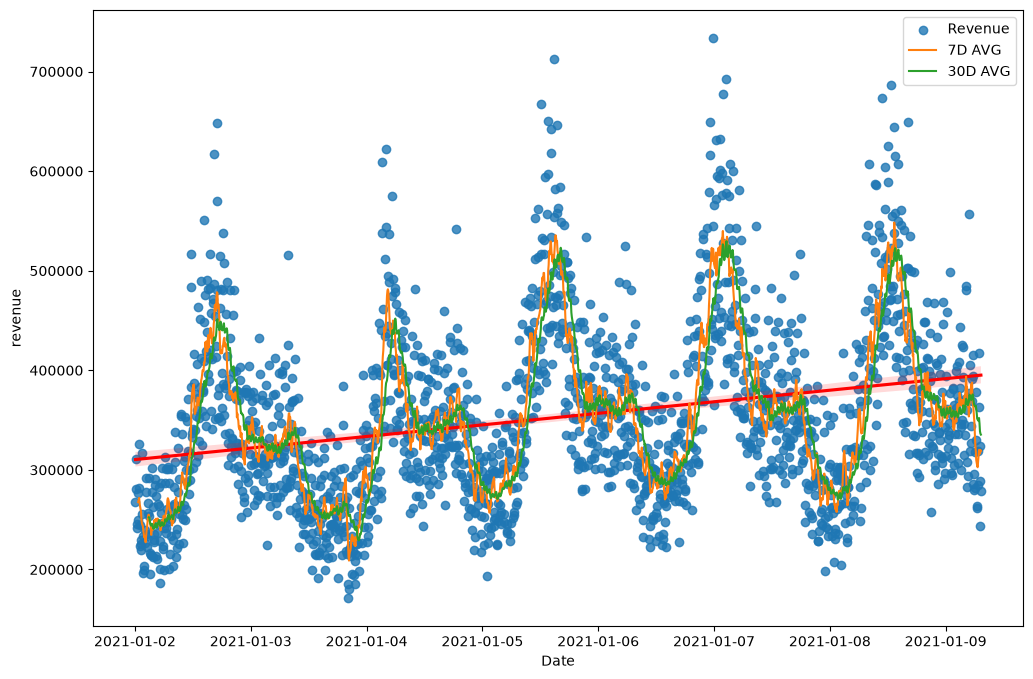

In [77]:
plt.figure(figsize=(12,8))
ax = sns.regplot(fact_sales_agg_daily, x='days_since_start', y='revenue', line_kws={'color':'red'}, label="Revenue");
sns.lineplot(fact_sales_agg_daily, x='days_since_start', y='revenue_7_d_avg', ax=ax, label="7D AVG")
sns.lineplot(fact_sales_agg_daily, x='days_since_start', y='revenue_30_d_avg', ax=ax, label='30D AVG')
ax.set_xticklabels(fact_sales_agg_daily['date']);
plt.xlabel("Date")
plt.legend()

In [70]:
fact_sales_agg_daily

,date,units_sold,revenue,stockout_attempts,stockout_units,revenue_7_d_avg,revenue_30_d_avg,days_since_start
0,2021-01-01,571.0,268031.22,1.0,1.0,NaN,NaN,1
1,2021-01-02,751.0,310675.78,2.0,2.0,NaN,NaN,2
2,2021-01-03,718.0,281026.97,4.0,7.0,NaN,NaN,3
3,2021-01-04,598.0,246080.98,3.0,6.0,NaN,NaN,4
4,2021-01-05,623.0,242066.65,4.0,6.0,NaN,NaN,5
...,...,...,...,...,...,...,...,...
1821,2025-12-27,902.0,417845.79,2.0,2.0,320068.831429,352046.574667,1822
1822,2025-12-28,718.0,323640.47,2.0,4.0,319157.422857,346666.906667,1823
1823,2025-12-29,533.0,243921.70,2.0,4.0,316306.784286,338772.316667,1824
1824,2025-12-30,575.0,288430.25,4.0,7.0,320109.660000,336375.598333,1825
